# The Ensemble Kalman Filter (EnKF)

Course: Recursive State Estimation for Dynamic Systems (SoSe 2026)

Institute: Geodätisches Institut Hannover

Team Members :

1.Arjun Mohandas( Matriculation Nummer:10081891)

2.Aswin Sam(Matriculation Nummer:10082498)

3.Edvin Tony Thampy(Matriculation Nummer:10082986)

This notebook implements the Ensemble kalman Filter (EnKF) for estimating the 3D position and velocity of a robot from noisy total-station observations.The unconstrained Enkf is implemented and documented.

The implementation follows the notation used in the lecture and exercise sessions.

## Use Of AI
ChatGPT was used for coding review, debugging assistance and researching information.It was mainly used to summarise topics and informations and document them into latex code including equations which were too lengthy and time consuming too write.It was used to understand and minimize code implementations and document information, handle data, plot graphs and diagrams with ease. It was mainly used to check for errors in code and evaluate diagrams to understand their behaviour.The implementations differed from filter to filter.Eventhough AI was used all implementation decisions and final results were verified by us.

## AIM

The Ensemble Kalman Filter (EnKF) aims to represent the uncertainty of the system using a collection of randomly generated state estimates called an **ensemble** instead of sigma points or  first order taylor series approximation.

This is acheived by propagating each ensemble member independently through the nonlinear process model. The predicted ensemble is then used to estimate the mean state and covariance. When new measurements become available, every ensemble member is updated individually using the Kalman gain.The covariance matrices are obtained directly from the spread of the ensemble members instead of being propagated analytically.

For an ensemble consisting of

$$
N_e
$$

members,

the ensemble is written as

$$
\left\{
\mathbf{x}^{(1)},
\mathbf{x}^{(2)},
\ldots,
\mathbf{x}^{(N_e)}
\right\}.
$$


# PRE-PROCESSING

## Imports and Loading given datafiles

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time

# Read observation and ground truth data
obsrv = pd.read_csv("Data/polar0011_slower_0.csv")
gtrue = pd.read_csv("Data/tracker0011_slower_0.csv")

In [2]:
#finding step length dt....

obsrv["time"] = pd.to_datetime(obsrv["Time [HH:MM:SS]"],format="%H:%M:%S.%f") # convert to timestamp 
time_inseconds=(obsrv["time"]-obsrv["time"].iloc[0]) # subtract the column from first timestap to get time in seconds
time_inseconds = time_inseconds.dt.total_seconds()# .dt.total_seconds to get seconds
time_inseconds= time_inseconds.values# convert to np arrays
dt= np.mean(np.diff(time_inseconds)) #Take mean of differences and round it.
dt=round(dt,3)

In [3]:
#Conversion of observations from polar coordinates to cartesian coordinates:
obsrv["H_radian"] = np.deg2rad(obsrv["H [deg]"]) #degree to radian conversion
obsrv["V_radian"]= np.deg2rad(obsrv["V [deg]"])
obsrv["D_m"]= obsrv["D [mm]"] / 1000  #mm to m conversion


X_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.cos(obsrv["H_radian"] )

Y_obsrv = obsrv["D_m"]*np.sin(obsrv["V_radian"])*np.sin(obsrv["H_radian"] )

Z_obsrv = obsrv["D_m"]*np.cos(obsrv["V_radian"])

obsrv["X_obsrv_cart"] = X_obsrv
obsrv["Y_obsrv_cart"] = Y_obsrv
obsrv["Z_obsrv_cart"] = Z_obsrv

X_gtrue = gtrue["X [m]"].values #converting pandas to numpy
Y_gtrue = gtrue["Y [m]"].values
Z_gtrue = gtrue["Z [m]"].values


In [4]:
#system matrices.....

#step length
dt=0.01 

#state_matrix

X0 = obsrv["X_obsrv_cart"].iloc[0]
Y0 = obsrv["Y_obsrv_cart"].iloc[0]
Z0 = obsrv["Z_obsrv_cart"].iloc[0]

X_k= np.array([X0,Y0,Z0,0,0,0])  # velocities are unknown initially

#Transition matrix
#The time step dt is use to build the transition matrix.
Phi_k = np.array([
    [1,0,0,dt,0,0],
    [0,1,0,0,dt,0],
    [0,0,1,0,0,dt],
    [0,0,0,1,0,0],
    [0,0,0,0,1,0],
    [0,0,0,0,0,1]])

sigma_a=2.5

#Then derive Q_ww usimg sigma_a:
Q_ww = sigma_a**2 * np.array([
    [dt**4/4,0,0,dt**3/2,0,0],
    [0,dt**4/4,0,0,dt**3/2,0],
    [0,0,dt**4/4,0,0,dt**3/2],
    [dt**3/2,0,0,dt**2,0,0],
    [0,dt**3/2,0,0,dt**2,0],
    [0,0,dt**3/2,0,0,dt**2]])


In [5]:
#Jacobian Function
#we should convert polar to cartesian using jacobian.
def observation_jacobian(H_radian, V_radian, D_m):
    return np.array([[-D_m * np.sin(V_radian) * np.sin(H_radian),
            D_m * np.cos(V_radian) * np.cos(H_radian),
            np.sin(V_radian) * np.cos(H_radian)],
            [D_m * np.sin(V_radian) * np.cos(H_radian),
            D_m * np.cos(V_radian) * np.sin(H_radian),
            np.sin(V_radian) * np.sin(H_radian)],
            [0,-D_m * np.sin(V_radian),np.cos(V_radian)]])


#Initial or State covariance matrix,Q_xx

sigma_H = np.deg2rad(0.0014)#given in task description
sigma_V = np.deg2rad(0.0014)#given in task description
D_0 = obsrv["D_m"].iloc[0] # Distance for zeroth measurement
sigma_D0 = 0.0025 * D_0+ 0.0025 # Equation provided in task description
Q_HVD0 = np.diag([
    sigma_H**2,
    sigma_V**2,
    sigma_D0**2])# Polar covariance matrix

J0 = observation_jacobian(
    obsrv["H_radian"].iloc[0],
    obsrv["V_radian"].iloc[0],
    obsrv["D_m"].iloc[0])

Q_XYZ0 = J0 @ Q_HVD0 @ J0.T

Q_xx = np.diag([
    Q_XYZ0[0,0],   # X variance
    Q_XYZ0[1,1],   # Y variance
    Q_XYZ0[2,2],   # Z variance
    1,             # Vx variance
    1,             # Vy variance
    1])            # Vz variance


In [6]:
## Nonlinear Observation Function
def h(x):
    X = x[0] 
    Y = x[1]
    Z = x[2]

    D = np.sqrt(X**2 + Y**2 + Z**2) #slope

    H = np.arctan2(Y,X)# horizontal angle

    V = np.arccos(Z/D) #zenith angle

    return np.array([H,V,D])

In [7]:
# Ensemble Settings
np.random.seed(77)
n=6 # state dimension
Ne = 500 # ensemble size

# PROCEDURE
# State and Measurement Models

The state vector is

$$
\mathbf{x}^{(k)}=
\begin{bmatrix}
X^{(k)}\\
Y^{(k)}\\
Z^{(k)}\\
V_X^{(k)}\\
V_Y^{(k)}\\
V_Z^{(k)}
\end{bmatrix}.
$$

The nonlinear dynamic system model is

$$
\mathbf{x}^{(k)}
=
\mathbf{\Phi}
\mathbf{x}^{(k-1)}
+
\mathbf{w}^{(k-1)},
$$

where

$$
\mathbf{w}^{(k-1)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{ww}
\right).
$$

The nonlinear observation model is

$$
\mathbf{l}^{(k)}
=
h
\left(
\mathbf{x}^{(k)}
\right)
+
\mathbf{v}^{(k)},
$$

where

$$
\mathbf{l}^{(k)}
=
\begin{bmatrix}
H^{(k)}\\
V^{(k)}\\
D^{(k)}
\end{bmatrix}
$$

The measurement noise is assumed to follow a Gaussian distribution,

$$
\mathbf{v}^{(k)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{R}^{(k)}
\right).
$$

## Ensemble Generation

An ensemble of $ N_e$ state vectors is generated from the current state estimate,

$$
\mathbf{X}_i^{(k)}
\sim
\mathcal{N}
\left(
\hat{\mathbf{X}}^{(k)},
\mathbf{Q}_{xx}^{(k)}
\right),
\qquad
i=1,\ldots,N_e.
$$

Each ensemble member represents one possible realization of the true system state.


In [8]:
# Ensemble Generation
#This function draws samples from the multivariate Gaussian distribution.
def generate_ensemble(X_k,Q_xx):
    ensemble = np.random.multivariate_normal(mean=X_k,cov=Q_xx,size=Ne).T
    return ensemble

## Prediction

Each ensemble member is propagated independently through the system model,

$$
\mathbf{X}_i^{(k)-}
=
\mathbf{\Phi}
\mathbf{X}_i^{(k-1)+}
+
\mathbf{w}_i^{(k-1)}.
$$

The predicted state estimate is obtained by averaging all predicted ensemble members,

$$
\hat{\mathbf{X}}^{(k)-}
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
\mathbf{X}_i^{(k)-},
$$

while the predicted covariance is estimated directly from the ensemble,

$$
\mathbf{Q}_{xx}^{(k)-}
=
\frac{1}{N_e-1}
\sum_{i=1}^{N_e}
\left(
\mathbf{X}_i^{(k)-}
-
\hat{\mathbf{X}}^{(k)-}
\right)
\left(
\mathbf{X}_i^{(k)-}
-
\hat{\mathbf{X}}^{(k)-}
\right)^T.
$$

To obtain an unbiased estimate of the covariance, the summation is divided by $$
N_e-1 $$ rather than $$ N_e$$ This correction is known as **Bessel's correction**, which compensates for the fact that the ensemble mean is itself estimated from the same ensemble members.


In [9]:
# Ensemble Prediction

def predict_ensemble(ensemble):

    # Predicted ensemble

    ensemble_minus = np.zeros_like(ensemble)

    for i in range(Ne):

        # Sample process noise

        w = np.random.multivariate_normal(mean=np.zeros(n),cov=Q_ww)

        # Propagate ensemble member

        ensemble_minus[:, i] = (Phi_k @ ensemble[:, i]+ w)

    return ensemble_minus    

In [10]:
# Forecast State Mean
# Axis=1 ensures the matrix has shape 6*100/ mean taken across each row
def predict_state_mean(ensemble_minus):
    X_k_minus = np.mean(ensemble_minus,axis=1)
    return X_k_minus

In [11]:
# Forecast State Covariance

def predict_state_covariance(ensemble_minus,X_k_minus):

    Q_xx_minus = np.zeros((n, n))

    for i in range(Ne):

        dx = (ensemble_minus[:, i]-X_k_minus)

        Q_xx_minus += np.outer(dx, dx)

    Q_xx_minus = Q_xx_minus / (Ne - 1)

    return Q_xx_minus

## Measurement Prediction

Each predicted ensemble member is propagated through the nonlinear measurement model,

$$
\mathbf{l}_i^{(k)}
=
h
\left(
\mathbf{X}_i^{(k)-}
\right).
$$

The predicted measurement is obtained as

$$
\hat{\mathbf{l}}^{(k)-}
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
\mathbf{l}_i^{(k)}.
$$

The predicted measurement covariance is

$$
\mathbf{Q}_{ll}^{(k)}
=
\frac{1}{N_e-1}
\sum_{i=1}^{N_e}
\left(
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}
\right)
\left(
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}
\right)^T
+
\mathbf{Q}_{HVD}^{(k)}.
$$

Similarly, the cross covariance is

$$
\mathbf{Q}_{xl}^{(k)}
=
\frac{1}{N_e-1}
\sum_{i=1}^{N_e}
\left(
\mathbf{X}_i^{(k)-}
-
\hat{\mathbf{X}}^{(k)-}
\right)
\left(\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}
\right)^T.
$$

In [12]:
# Predicted Measurement Ensemble

def predict_measurement_ensemble(ensemble_minus):

    measurement_ensemble = np.zeros((3, Ne))

    for i in range(Ne):

        measurement_ensemble[:, i] = h(ensemble_minus[:, i])

    return measurement_ensemble

## Predicted Measurement Mean

After propagating every predicted ensemble member through the nonlinear observation model, the predicted measurement is obtained by averaging the predicted measurement ensemble.

The predicted measurement vector is

$$
\hat{\mathbf{l}}^{(k)-}
=
\begin{bmatrix}
\hat{H}^{(k)-}\\
\hat{V}^{(k)-}\\
\hat{D}^{(k)-}
\end{bmatrix}.
$$

The vertical angle and distance are computed using the arithmetic mean,

$$
\hat{V}^{(k)-}
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
V_i^{(k)},
$$

$$
\hat{D}^{(k)-}
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
D_i^{(k)}.
$$

Since the horizontal angle is a circular quantity, its mean cannot be computed using the arithmetic average.

Instead,

$$
S
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
\sin\!\left(H_i^{(k)}\right),
$$

$$
C
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
\cos\!\left(H_i^{(k)}\right),
$$

and the circular mean is

$$
\hat{H}^{(k)-}
=
\operatorname{atan2}(S,C).
$$

Using the circular mean prevents discontinuities caused by angle wrapping at $\pm\pi$ and provides the correct average horizontal angle.


In [13]:
# Predicted Measurement Mean

def predict_measurement_mean(measurement_ensemble):

    l_k_minus = np.zeros(3)

    # Horizontal angle (Circular Mean)

    sin_sum = 0.0
    cos_sum = 0.0

    for i in range(Ne):

        sin_sum += np.sin(measurement_ensemble[0, i])

        cos_sum += np.cos(measurement_ensemble[0, i])

    l_k_minus[0] = np.arctan2(sin_sum,cos_sum)

    # Vertical Angle

    l_k_minus[1] = np.mean(measurement_ensemble[1, :])

    # Distance

    l_k_minus[2] = np.mean(measurement_ensemble[2, :])

    return l_k_minus

## Predicted Measurement Covariance

After computing the predicted measurement mean, the uncertainty of the predicted measurements is estimated from the spread of the measurement ensemble.

The deviation of the \(i^{\text{th}}\) predicted measurement from the predicted measurement mean is

$$
\Delta\mathbf{l}_i^{(k)}
=
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}.
$$

The predicted measurement covariance is computed using the sample covariance,

$$
\mathbf{Q}_{ll}^{(k)}
=
\frac{1}{N_e-1}
\sum_{i=1}^{N_e}
\Delta\mathbf{l}_i^{(k)}
\Delta\mathbf{l}_i^{(k)T}.
$$

Finally, the measurement noise covariance is added,

$$
\mathbf{Q}_{ll}^{(k)}
=
\mathbf{Q}_{ll}^{(k)}
+
\mathbf{Q}_{HVD}^{(k)}.
$$

The resulting covariance represents the uncertainty of the predicted measurements due to both the spread of the ensemble and the measurement noise.

In [14]:
# Predicted Measurement Covariance

def predict_measurement_covariance(measurement_ensemble,l_k_minus,Q_HVD):

    Q_zz = np.zeros((3,3))

    for i in range(Ne):

        dz = (measurement_ensemble[:, i]- l_k_minus)

        # Horizontal angle wrapping

        dz[0] = np.arctan2(
            np.sin(dz[0]),
            np.cos(dz[0]))

        Q_zz += np.outer(dz,dz)

    # Sample covariance

    Q_zz = Q_zz / (Ne - 1)

    # Add measurement noise

    Q_zz += Q_HVD

    return Q_zz

## Perturbed Observations

In the stochastic Ensemble Kalman Filter, each ensemble member is updated using a different realization of the measurement.

The perturbed observation corresponding to the \(i^{\text{th}}\) ensemble member is

$$
\mathbf{l}_i^{(k)}
=
\mathbf{l}^{(k)}
+
\mathbf{v}_i^{(k)},
$$

where

$$
\mathbf{v}_i^{(k)}
\sim
\mathcal{N}
\left(
\mathbf{0},
\mathbf{Q}_{HVD}^{(k)}
\right).
$$

The complete perturbed observation ensemble is

$$
\mathbf{L}^{(k)}
=
\left[
\mathbf{l}_1^{(k)},
\mathbf{l}_2^{(k)},
\cdots,
\mathbf{l}_{N_e}^{(k)}
\right].
$$

Each ensemble member is therefore updated using a slightly different realization of the measurement. This prevents the ensemble from collapsing and preserves the correct measurement uncertainty throughout the update process.

In [15]:
# Perturbed Observations
def generate_perturbed_observations(l_k,Q_HVD):
    perturbed_observations = np.zeros((3, Ne))
    
    for i in range(Ne):
        
        V_k = np.random.multivariate_normal(mean=np.zeros(3),cov=Q_HVD)

        perturbed_observations[:, i] = (l_k + V_k)

    return perturbed_observations 

## Cross Covariance

The cross covariance describes the statistical relationship between the predicted state ensemble and the predicted measurement ensemble.

The deviation of the \(i^{\text{th}}\) predicted state ensemble member is

$$
\Delta\mathbf{X}_i^{(k)}
=
\mathbf{X}_i^{(k)-}
-
\hat{\mathbf{X}}^{(k)-},
$$

and the deviation of the corresponding predicted measurement is

$$
\Delta\mathbf{l}_i^{(k)}
=
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}^{(k)-}.
$$

The predicted cross covariance is computed using the sample covariance,

$$
\mathbf{Q}_{xl}^{(k)}
=
\frac{1}{N_e-1}
\sum_{i=1}^{N_e}
\Delta\mathbf{X}_i^{(k)}
\Delta\mathbf{l}_i^{(k)T}.
$$

The cross covariance measures the statistical relationship between the uncertainty in the predicted state and the uncertainty in the predicted measurements. It provides the link between the state space and the measurement space and is used to compute the Kalman gain.

In [16]:
# Cross Covariance

def predict_cross_covariance(ensemble_minus,X_k_minus,measurement_ensemble,l_k_minus):

    Q_xz = np.zeros((n, 3))

    for i in range(Ne):

        dx = (ensemble_minus[:, i]- X_k_minus)

        dz = (measurement_ensemble[:, i]- l_k_minus)

        # Horizontal angle wrapping

        dz[0] = np.arctan2(
            np.sin(dz[0]),
            np.cos(dz[0]))

        Q_xz += np.outer(dx,dz)

    # Sample covariance

    Q_xz = Q_xz / (Ne - 1)

    return Q_xz

## Kalman Gain

The Kalman gain is computed as

$$
\mathbf{K}^{(k)}
=
\mathbf{Q}_{xl}^{(k)}
\left(
\mathbf{Q}_{ll}^{(k)}
\right)^{-1}.
$$

The Kalman gain determines how much the predicted state should be corrected using the measurement information.

In [17]:
# Kalman Gain
def compute_kalman_gain(Q_xz,Q_zz):

    K_k = (Q_xz@ np.linalg.inv(Q_zz))

    return K_k

## Innovation (Measurement Residual)

The innovation represents the difference between the perturbed observation and the predicted measurement for each ensemble member.

For the \(i^{\text{th}}\) ensemble member,

$$
\mathbf{I}_i^{(k)}
=
\mathbf{l}_i^{(k)}
-
\hat{\mathbf{l}}_i^{(k)}.
$$

where

$$
\hat{\mathbf{l}}_i^{(k)}
=
h\!\left(
\mathbf{X}_i^{(k)-}
\right)
$$

is the predicted measurement corresponding to the predicted ensemble member.

Since the first measurement component is the horizontal angle, the innovation must be wrapped to the interval

$$
[-\pi,\pi]
$$

using

$$
I_H^{(k)}
=
\operatorname{atan2}
\left(
\sin\!\left(I_H^{(k)}\right),
\cos\!\left(I_H^{(k)}\right)
\right).
$$

The innovation is then used to update each ensemble member independently.

In [18]:
# Innovation

def innovation(perturbed_observations,measurement_ensemble):

    innovation_ensemble = np.zeros_like(perturbed_observations)

    for i in range(Ne):

        innovation_ensemble[:, i] = (perturbed_observations[:, i]-measurement_ensemble[:, i])

        # Horizontal angle wrapping

        innovation_ensemble[0, i] = np.arctan2(np.sin(innovation_ensemble[0, i]),np.cos(innovation_ensemble[0, i]))

    return innovation_ensemble

## Ensemble Update

Each ensemble member is updated independently using a perturbed observation,

$$
\mathbf{X}_i^{(k)+}
=
\mathbf{X}_i^{(k)-}
+
\mathbf{K}^{(k)}
\left(
\mathbf{l}_i^{(k)}
-
h\!\left(\mathbf{X}_i^{(k)-}\right)
\right).
$$

Thus, every ensemble member is updated independently using its own perturbed observation, producing the posterior ensemble.

In [19]:
# Ensemble Update

def update_ensemble(ensemble_minus,K_k,innovation_ensemble):

    ensemble_plus = np.zeros_like(ensemble_minus)

    for i in range(Ne):

        ensemble_plus[:, i] = (ensemble_minus[:, i]+K_k @ innovation_ensemble[:, i])

    return ensemble_plus

## Posterior State Estimate

The final state estimate is obtained by averaging the updated ensemble,

$$
\hat{\mathbf{X}}^{(k)+}
=
\frac{1}{N_e}
\sum_{i=1}^{N_e}
\mathbf{X}_i^{(k)+},
$$

and the posterior covariance is

$$
\mathbf{Q}_{xx}^{(k)+}
=
\frac{1}{N_e-1}
\sum_{i=1}^{N_e}
\left(
\mathbf{X}_i^{(k)+}
-
\hat{\mathbf{X}}^{(k)+}
\right)
\left(
\mathbf{X}_i^{(k)+}
-
\hat{\mathbf{X}}^{(k)+}
\right)^T.
$$


In [20]:
# Posterior State Estimate

def update_state_mean(ensemble_plus):

    X_k_plus = np.mean(ensemble_plus,axis=1)

    return X_k_plus

In [21]:
# Posterior Covariance
def update_covariance(ensemble_plus,X_k_plus):

    Q_xx_plus = np.zeros((n, n))

    for i in range(Ne):

        dx = (ensemble_plus[:, i]-X_k_plus)

        Q_xx_plus += np.outer(dx,dx)

    Q_xx_plus = Q_xx_plus / (Ne - 1)

    return Q_xx_plus
    

In [22]:
N = len(obsrv)

estimates_enkf= np.zeros((N,6))
X_plus_history_enkf= np.zeros((N, 6))
Q_plus_history_enkf = np.zeros((N, 6, 6))

estimates_enkf[0] = X_k
X_plus_history_enkf[0] = X_k
Q_plus_history_enkf[0] = Q_xx

# Start Timing
start_time = time.perf_counter()

for k in range(1, N):

    #Actual Measuremnent

    l_k = np.array([
        obsrv["H_radian"].iloc[k],
        obsrv["V_radian"].iloc[k],
        obsrv["D_m"].iloc[k]])
    
#Observation/measurement covariance
    
    sigma_H = np.deg2rad(0.0014) # given 

    sigma_V = np.deg2rad(0.0014) #given

    sigma_D = (0.0025 *obsrv["D_m"].iloc[k]+ 0.0025) #given

    Q_HVD = np.diag([sigma_H**2,
                             sigma_V**2,
                             sigma_D**2])   
    
    # Forecast

    ensemble = generate_ensemble(X_k,Q_xx)

    ensemble_minus = predict_ensemble(ensemble)

    X_k_minus = predict_state_mean(ensemble_minus)

    Q_xx_minus = predict_state_covariance(ensemble_minus,X_k_minus)

    # Measurement Prediction
    
    measurement_ensemble = predict_measurement_ensemble(ensemble_minus)

    l_k_minus = predict_measurement_mean(measurement_ensemble)

    Q_zz = predict_measurement_covariance(measurement_ensemble,l_k_minus,Q_HVD)

    # Perturbed Observations

    perturbed_observations = generate_perturbed_observations(l_k,Q_HVD)

    # Cross Covariance

    Q_xz = predict_cross_covariance(ensemble_minus,X_k_minus,measurement_ensemble,l_k_minus)

    # Kalman Gain

    K_k = compute_kalman_gain(Q_xz,Q_zz)

    # Innovation

    innovation_ensemble = innovation(perturbed_observations,measurement_ensemble)

    # Ensemble Update

    ensemble_plus = update_ensemble(ensemble_minus,K_k,innovation_ensemble)

    # Posterior Statistics

    X_k_plus = update_state_mean(ensemble_plus)

    Q_xx_plus = update_covariance(ensemble_plus,X_k_plus)

    # Save Results
  
    estimates_enkf[k] = X_k_plus

    X_plus_history_enkf[k] = X_k_plus

    Q_plus_history_enkf[k] = Q_xx_plus

    # Update Next Epoch

    X_k = X_k_plus

    Q_xx = Q_xx_plus

    # Stop Timing
    
    end_time = time.perf_counter()

    computation_time = end_time - start_time

#Extracting Estimates....

X_est = estimates_enkf[:,0]

Y_est = estimates_enkf[:,1]

Z_est = estimates_enkf[:,2]

Vx_est = estimates_enkf[:,3]

Vy_est = estimates_enkf[:,4]

Vz_est = estimates_enkf[:,5]

print("="*60)
print("COMPUTATION TIME FOR ENKF")
print("="*60)

print(f"Total Time : {computation_time:.6f} s")

print(f"Average Time per Epoch : {computation_time/(N-1):.8f} s")

print(f"Average Time per Epoch : {(computation_time/(N-1))*1000:.4f} ms")

print("="*60)


COMPUTATION TIME FOR ENKF
Total Time : 949.256085 s
Average Time per Epoch : 0.13453176 s
Average Time per Epoch : 134.5318 ms


In [23]:
# ENKF RESULTS
# Position RMSE

rmse_x = np.sqrt(np.mean((X_est - X_gtrue)**2))
rmse_y = np.sqrt(np.mean((Y_est - Y_gtrue)**2))
rmse_z = np.sqrt(np.mean((Z_est - Z_gtrue)**2))

# Ground-truth velocities

Vx_true = np.gradient(X_gtrue, dt)
Vy_true = np.gradient(Y_gtrue, dt)
Vz_true = np.gradient(Z_gtrue, dt)

# Velocity RMSE

rmse_vx = np.sqrt(np.mean((Vx_est - Vx_true)**2))
rmse_vy = np.sqrt(np.mean((Vy_est - Vy_true)**2))
rmse_vz = np.sqrt(np.mean((Vz_est - Vz_true)**2))

# Overall 3D RMSE

position_rmse = np.sqrt(
    rmse_x**2 +
    rmse_y**2 +
    rmse_z**2)

velocity_rmse = np.sqrt(
    rmse_vx**2 +
    rmse_vy**2 +
    rmse_vz**2)

print("="*60)
print("ENKF RESULTS")
print("="*60)

print(f"RMSE X  (m)    : {rmse_x:.12f}")
print(f"RMSE Y  (m)    : {rmse_y:.12f}")
print(f"RMSE Z  (m)    : {rmse_z:.12f}")

print()

print(f"RMSE Vx (m/s)  : {rmse_vx:.12f}")
print(f"RMSE Vy (m/s)  : {rmse_vy:.12f}")
print(f"RMSE Vz (m/s)  : {rmse_vz:.12f}")

print()

print(f"3D Position RMSE (m) : {position_rmse:.12f}")
print(f"3D Velocity RMSE (m/s): {velocity_rmse:.12f}")

ENKF RESULTS
RMSE X  (m)    : 0.004000303523
RMSE Y  (m)    : 0.004124689343
RMSE Z  (m)    : 0.000362037925

RMSE Vx (m/s)  : 0.039302095974
RMSE Vy (m/s)  : 0.039809670872
RMSE Vz (m/s)  : 0.017618695811

3D Position RMSE (m) : 0.005757305091
3D Velocity RMSE (m/s): 0.058650516493


## OBSERVATIONS
## 1.2D Estimated EnKF vs Ground Truth Trajectory

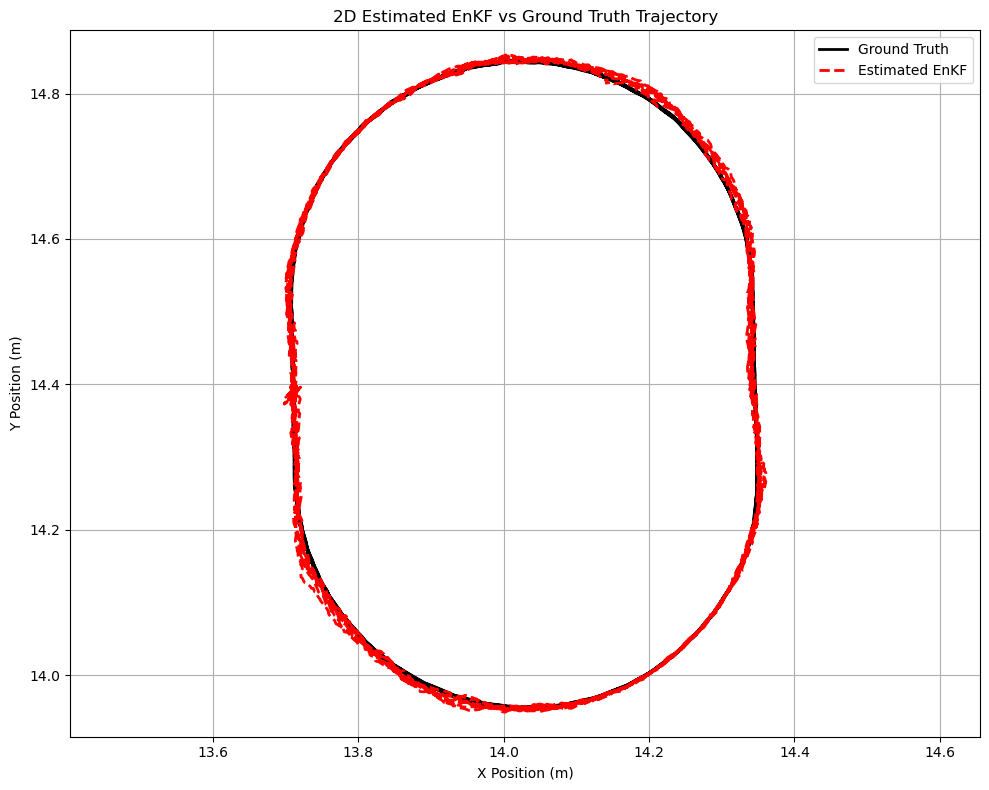

In [24]:
plt.figure(figsize=(10, 8))

# Ground Truth
plt.plot(
    X_gtrue,
    Y_gtrue,
    color='black',
    linewidth=2,
    label='Ground Truth')

# EnKF Estimate
plt.plot(
    X_est,
    Y_est,
    color='red',
    linestyle='--',
    linewidth=2,
    label='Estimated EnKF')

plt.xlabel("X Position (m)")
plt.ylabel("Y Position (m)")

plt.title("2D Estimated EnKF vs Ground Truth Trajectory")

plt.axis('equal')
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_2D_Trajectory.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

- The two-dimensional trajectory comparison demonstrates that the Ensemble Kalman Filter (EnKF) accurately estimates the vehicle trajectory, with the ensemble mean closely following the ground truth throughout the complete experiment. The estimated trajectory closely overlaps the reference path along both the straight and curved sections, indicating good estimation accuracy despite the stochastic nature of the EnKF.

- A slightly larger spread of the estimated trajectory is observed compared with the LKF, EKF, IEKF, and UKF because the EnKF estimates the system state using an ensemble of particles. This spread represents the uncertainty captured by the ensemble and is an inherent characteristic of the algorithm.

- Small deviations occur primarily within the curved sections of the trajectory where the vehicle undergoes continuous changes in direction and the nonlinear motion becomes more challenging to estimate.

- The estimated trajectory remains smooth and continuous without evidence of filter divergence or numerical instability, demonstrating that the selected ensemble size and covariance parameters provide stable estimation.

- Overall, the EnKF provides accurate and numerically stable trajectory estimation while effectively representing uncertainty through ensemble statistics, making it a suitable alternative to Jacobian-based and sigma-point-based nonlinear filtering methods.

## 2. Component wise Absolute deviation between estimated and ground truth 3D position over time

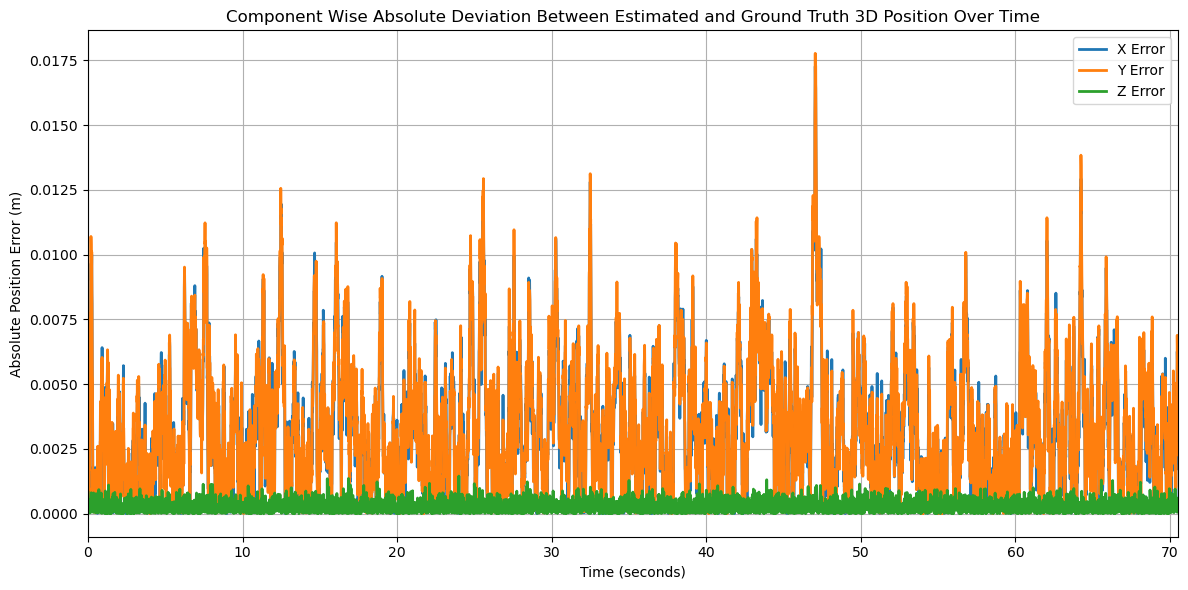

ABSOLUTE POSITION DEVIATIONS
Maximum X Deviation (m) : 0.017265895461
Mean X Deviation (m)    : 0.003226359380

Maximum Y Deviation (m) : 0.017765032659
Mean Y Deviation (m)    : 0.003325199997

Maximum Z Deviation (m) : 0.001451012362
Mean Z Deviation (m)    : 0.000289022643


In [25]:
err_x = np.abs(X_est - X_gtrue)
err_y = np.abs(Y_est - Y_gtrue)
err_z = np.abs(Z_est - Z_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_x, linewidth=2, label='X Error')
plt.plot(time_inseconds, err_y, linewidth=2, label='Y Error')
plt.plot(time_inseconds, err_z, linewidth=2, label='Z Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Position Error (m)")

plt.title("Component Wise Absolute Deviation Between Estimated and Ground Truth 3D Position Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_Position_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Component-wise Maximum and Mean Absolute Position Deviation
max_x = np.max(err_x)
max_y = np.max(err_y)
max_z = np.max(err_z)

mean_x = np.mean(err_x)
mean_y = np.mean(err_y)
mean_z = np.mean(err_z)

print("="*60)
print("ABSOLUTE POSITION DEVIATIONS")
print("="*60)

print(f"Maximum X Deviation (m) : {max_x:.12f}")
print(f"Mean X Deviation (m)    : {mean_x:.12f}")
print()

print(f"Maximum Y Deviation (m) : {max_y:.12f}")
print(f"Mean Y Deviation (m)    : {mean_y:.12f}")
print()

print(f"Maximum Z Deviation (m) : {max_z:.12f}")
print(f"Mean Z Deviation (m)    : {mean_z:.12f}")

print("="*60)

- The component-wise absolute position deviations remain bounded throughout the complete trajectory, demonstrating that the Ensemble Kalman Filter (EnKF) provides stable recursive position estimation despite the stochastic nature of the ensemble representation.

- The mean absolute position errors are approximately **3.23 mm**, **3.33 mm**, and **0.29 mm** for the $X$, $Y$, and $Z$ components, respectively, indicating accurate three-dimensional position estimation.

- The horizontal position components ($X$ and $Y$) exhibit larger deviations than the vertical component because the vehicle motion primarily occurs within the horizontal plane, where changes in direction continuously influence the state estimates.

- Compared with the LKF, EKF, IEKF, and UKF, the EnKF exhibits slightly larger instantaneous fluctuations in the horizontal position errors. These fluctuations arise naturally from the ensemble-based approximation of the state probability distribution rather than from numerical instability.

- The largest position deviations occur mainly during the curved sections of the trajectory where the robot undergoes continuous changes in direction and the nonlinear system dynamics become more pronounced.

- The position deviations remain bounded throughout the experiment without evidence of filter divergence or covariance instability, confirming that the selected ensemble size and covariance parameters provide stable estimation.

- The comparatively small vertical position errors indicate that the EnKF accurately estimates the vertical motion, while the slightly larger horizontal deviations reflect the increased uncertainty associated with lateral vehicle dynamics.

- Overall, the Ensemble Kalman Filter provides accurate and numerically stable three-dimensional position estimation while naturally accounting for uncertainty through ensemble statistics.

## 3. Component wise Absolute deviation between estimated and ground truth 3D velocity over time

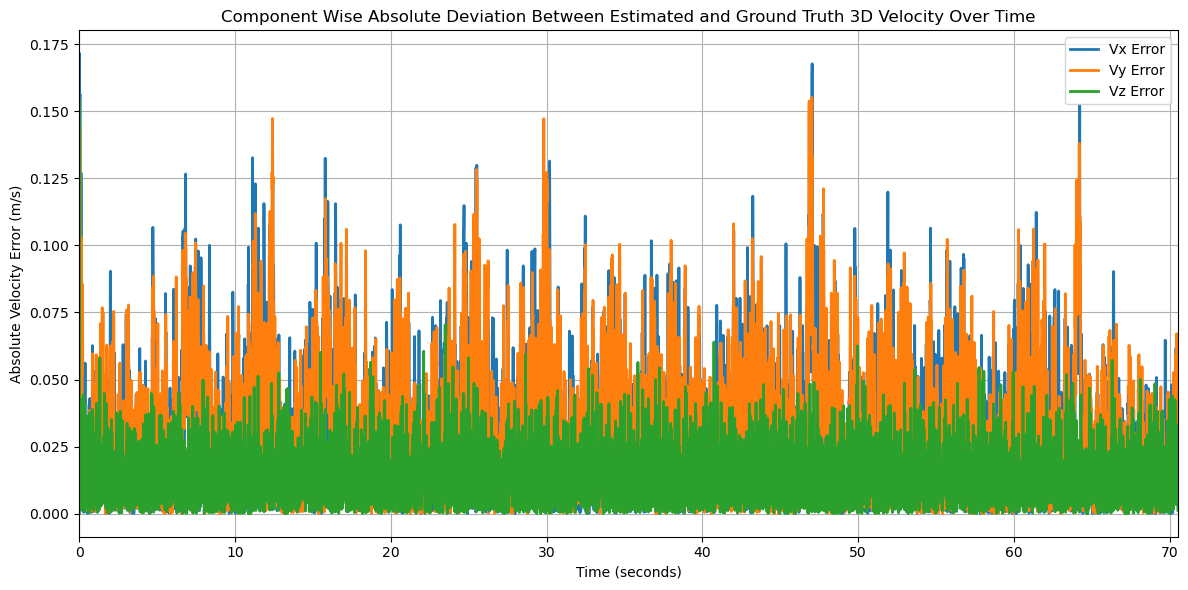

ABSOLUTE VELOCITY DEVIATIONS
Maximum Vx Deviation (m/s) : 0.171531891223
Mean Vx Deviation (m/s)    : 0.030894369528

Maximum Vy Deviation (m/s) : 0.155145701321
Mean Vy Deviation (m/s)    : 0.031567016862

Maximum Vz Deviation (m/s) : 0.154330021263
Mean Vz Deviation (m/s)    : 0.014045308926


In [26]:
# Ground Truth Velocity
Vx_gtrue = np.gradient(X_gtrue, dt)
Vy_gtrue = np.gradient(Y_gtrue, dt)
Vz_gtrue = np.gradient(Z_gtrue, dt)

err_vx = np.abs(Vx_est - Vx_gtrue)
err_vy = np.abs(Vy_est - Vy_gtrue)
err_vz = np.abs(Vz_est - Vz_gtrue)

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, err_vx, linewidth=2, label='Vx Error')
plt.plot(time_inseconds, err_vy, linewidth=2, label='Vy Error')
plt.plot(time_inseconds, err_vz, linewidth=2, label='Vz Error')

plt.xlabel("Time (seconds)")
plt.ylabel("Absolute Velocity Error (m/s)")

plt.title("Component Wise Absolute Deviation Between Estimated and Ground Truth 3D Velocity Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_Velocity_Absolute_Deviation.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Component-wise Maximum and Mean Absolute Velocity Deviation
max_vx = np.max(err_vx)
max_vy = np.max(err_vy)
max_vz = np.max(err_vz)

mean_vx = np.mean(err_vx)
mean_vy = np.mean(err_vy)
mean_vz = np.mean(err_vz)

print("="*60)
print("ABSOLUTE VELOCITY DEVIATIONS")
print("="*60)

print(f"Maximum Vx Deviation (m/s) : {max_vx:.12f}")
print(f"Mean Vx Deviation (m/s)    : {mean_vx:.12f}")
print()

print(f"Maximum Vy Deviation (m/s) : {max_vy:.12f}")
print(f"Mean Vy Deviation (m/s)    : {mean_vy:.12f}")
print()

print(f"Maximum Vz Deviation (m/s) : {max_vz:.12f}")
print(f"Mean Vz Deviation (m/s)    : {mean_vz:.12f}")

print("="*60)

- The component-wise absolute velocity deviations remain bounded throughout the complete trajectory, demonstrating that the Ensemble Kalman Filter (EnKF) provides stable recursive velocity estimation while explicitly accounting for uncertainty through an ensemble of state realizations.

- The mean absolute velocity errors are approximately **0.0309 m/s**, **0.0316 m/s**, and **0.0140 m/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, indicating accurate three-dimensional velocity estimation.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger deviations than the vertical component because the robots motion occurs predominantly within the horizontal plane, where continuous changes in direction introduce greater dynamic uncertainty.

- Compared with the LKF, EKF, IEKF, and UKF, the EnKF exhibits slightly larger instantaneous fluctuations in the horizontal velocity errors. These fluctuations are expected since the EnKF estimates the state using a finite ensemble of particles, resulting in statistical sampling variability rather than deterministic state updates.

- The largest velocity deviations occur primarily during the curved sections of the trajectory where the vehicle undergoes continuous changes in direction and the nonlinear system dynamics become more significant.

- The velocity deviations remain bounded throughout the experiment without evidence of filter divergence or covariance instability, confirming that the selected ensemble size and covariance parameters provide numerically stable recursive estimation.

- The comparatively small vertical velocity errors indicate that the EnKF accurately estimates the vertical motion, while the slightly larger horizontal deviations reflect the increased uncertainty associated with lateral robot dynamics.

- Overall, the Ensemble Kalman Filter provides accurate and numerically stable three-dimensional velocity estimation while naturally representing estimation uncertainty through ensemble statistics, making it well suited for nonlinear tracking problems.

## 4. Component Wise Cumulative RMSE for 3D position over time

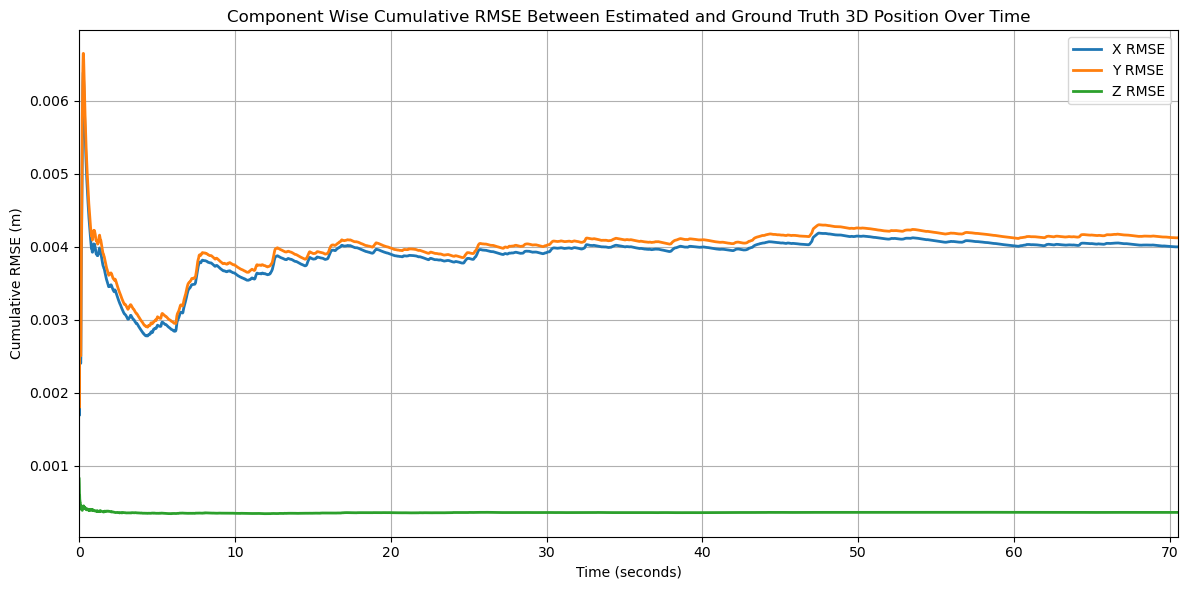

FINAL POSITION RMSE
RMSE X = 0.004000304 m (4.000 mm)
RMSE Y = 0.004124689 m (4.125 mm)
RMSE Z = 0.000362038 m (0.362 mm)


In [27]:
cum_rmse_x = np.zeros(len(X_est))
cum_rmse_y = np.zeros(len(Y_est))
cum_rmse_z = np.zeros(len(Z_est))

for k in range(1, len(X_est) + 1):

    cum_rmse_x[k-1] = np.sqrt(
        np.mean((X_est[:k] - X_gtrue[:k])**2))

    cum_rmse_y[k-1] = np.sqrt(
        np.mean((Y_est[:k] - Y_gtrue[:k])**2))

    cum_rmse_z[k-1] = np.sqrt(
        np.mean((Z_est[:k] - Z_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, cum_rmse_x, linewidth=2, label='X RMSE')
plt.plot(time_inseconds, cum_rmse_y, linewidth=2, label='Y RMSE')
plt.plot(time_inseconds, cum_rmse_z, linewidth=2, label='Z RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m)")

plt.title("Component Wise Cumulative RMSE Between Estimated and Ground Truth 3D Position Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_Component_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Position RMSE

print("="*60)
print("FINAL POSITION RMSE")
print("="*60)

print(f"RMSE X = {cum_rmse_x[-1]:.9f} m ({cum_rmse_x[-1]*1000:.3f} mm)")
print(f"RMSE Y = {cum_rmse_y[-1]:.9f} m ({cum_rmse_y[-1]*1000:.3f} mm)")
print(f"RMSE Z = {cum_rmse_z[-1]:.9f} m ({cum_rmse_z[-1]*1000:.3f} mm)")

print("="*60)

- The cumulative position RMSE converges rapidly after the initial transient period and remains nearly constant throughout the experiment, demonstrating stable recursive estimation by the Ensemble Kalman Filter (EnKF).

- The final RMSE values are approximately **4.000 mm**, **4.125 mm**, and **0.362 mm** for the $X$, $Y$, and $Z$ position components, respectively, indicating consistent three-dimensional position estimation.

- The horizontal position components ($X$ and $Y$) exhibit larger RMSE values than the vertical component because the vehicle motion occurs predominantly within the horizontal plane, where changes in direction introduce greater estimation uncertainty.

- Compared with the Linear Kalman Filter (LKF), Extended Kalman Filter (EKF), Iterated Extended Kalman Filter (IEKF), and Unscented Kalman Filter (UKF), the EnKF produces slightly higher cumulative position RMSE. This behaviour is expected because the EnKF approximates the state probability distribution using a finite ensemble, introducing statistical sampling errors into the estimation process.

- Despite the increased RMSE, the cumulative error remains bounded throughout the experiment without evidence of divergence or numerical instability, confirming that the selected ensemble size provides stable recursive estimation.

- The comparatively small RMSE in the vertical position component demonstrates that the EnKF accurately estimates the relatively smooth vertical motion, while the slightly larger horizontal errors reflect the increased uncertainty associated with robots dynamics.

- The cumulative RMSE curves exhibit smooth convergence without abrupt oscillations, indicating that the process and measurement noise parameters are appropriately selected for the estimation problem.

- Overall, the Ensemble Kalman Filter provides accurate and numerically stable three-dimensional position estimation. Although its cumulative position RMSE is slightly higher than that of the deterministic Kalman filter variants, it effectively captures estimation uncertainty through ensemble statistics while maintaining reliable tracking performance.

## 5. Overall 3D position RMSE over time ( Computed for Easier Comparison)

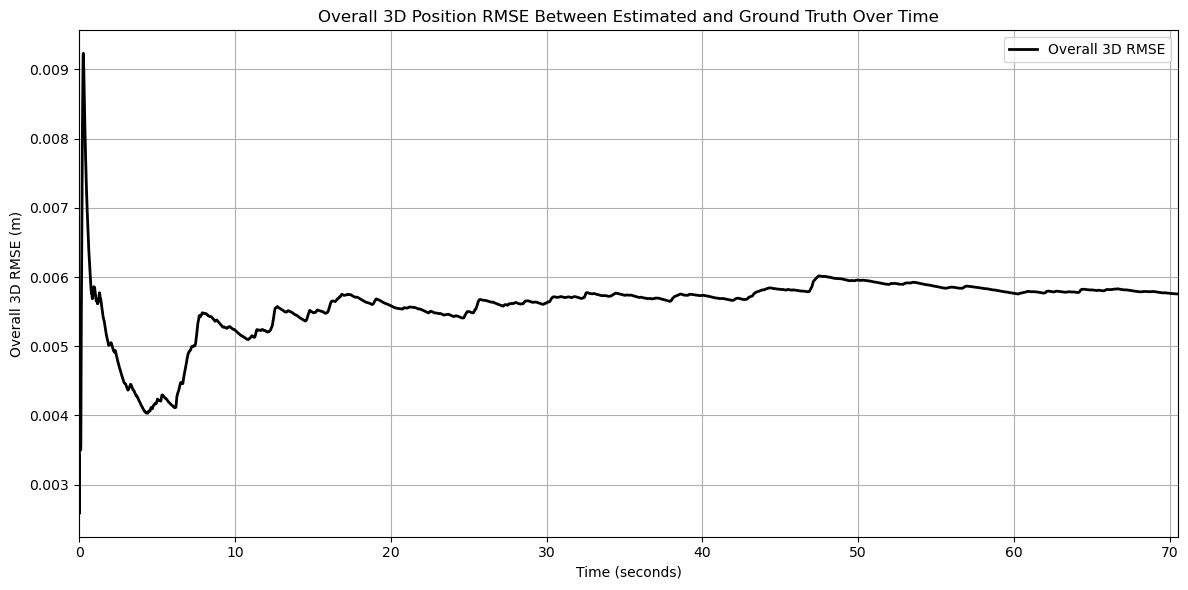

Overall 3D RMSE = 0.005757305 m (5.757 mm)


In [28]:
cum_rmse_3d = np.zeros(len(X_est))

for k in range(1, len(X_est) + 1):

    error_squared = (
        (X_est[:k] - X_gtrue[:k])**2 +
        (Y_est[:k] - Y_gtrue[:k])**2 +
        (Z_est[:k] - Z_gtrue[:k])**2)

    cum_rmse_3d[k-1] = np.sqrt(
        np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_3d,
    linewidth=2,
    color='black',
    label='Overall 3D RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D RMSE (m)")

plt.title("Overall 3D Position RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_Overall_Cumulative_PositionRMSE.png",
    dpi=300,
    bbox_inches="tight")


plt.show()

# Final Overall 3D Position RMSE

overall_rmse = cum_rmse_3d[-1]

print("="*60)
print(f"Overall 3D RMSE = {overall_rmse:.9f} m ({overall_rmse*1000:.3f} mm)")
print("="*60)

## 6. Component wise Cumulative 3D velocity RMSE over time

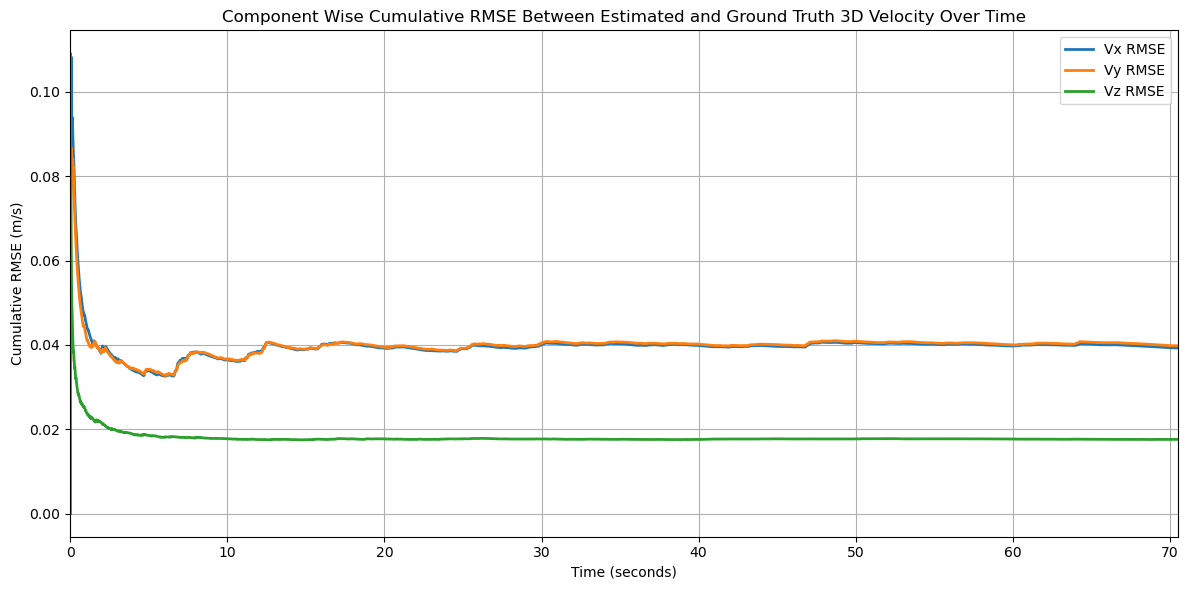

FINAL VELOCITY RMSE
RMSE Vx = 0.039302096 m/s (39.302 mm/s)
RMSE Vy = 0.039809671 m/s (39.810 mm/s)
RMSE Vz = 0.017618696 m/s (17.619 mm/s)


In [29]:
cum_rmse_vx = np.zeros(len(Vx_est))
cum_rmse_vy = np.zeros(len(Vy_est))
cum_rmse_vz = np.zeros(len(Vz_est))

for k in range(1, len(Vx_est) + 1):

    cum_rmse_vx[k-1] = np.sqrt(
        np.mean((Vx_est[:k] - Vx_gtrue[:k])**2))

    cum_rmse_vy[k-1] = np.sqrt(
        np.mean((Vy_est[:k] - Vy_gtrue[:k])**2))

    cum_rmse_vz[k-1] = np.sqrt(
        np.mean((Vz_est[:k] - Vz_gtrue[:k])**2))

plt.figure(figsize=(12,6))

plt.plot(time_inseconds, cum_rmse_vx, linewidth=2, label='Vx RMSE')
plt.plot(time_inseconds, cum_rmse_vy, linewidth=2, label='Vy RMSE')
plt.plot(time_inseconds, cum_rmse_vz, linewidth=2, label='Vz RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Cumulative RMSE (m/s)")

plt.title("Component Wise Cumulative RMSE Between Estimated and Ground Truth 3D Velocity Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_Component_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")


plt.show()

# Final Velocity RMSE

print("="*60)
print("FINAL VELOCITY RMSE")
print("="*60)

print(f"RMSE Vx = {cum_rmse_vx[-1]:.9f} m/s ({cum_rmse_vx[-1]*1000:.3f} mm/s)")
print(f"RMSE Vy = {cum_rmse_vy[-1]:.9f} m/s ({cum_rmse_vy[-1]*1000:.3f} mm/s)")
print(f"RMSE Vz = {cum_rmse_vz[-1]:.9f} m/s ({cum_rmse_vz[-1]*1000:.3f} mm/s)")

print("="*60)

- The cumulative velocity RMSE converges rapidly after the initial transient period and remains nearly constant throughout the experiment, demonstrating stable recursive velocity estimation by the Ensemble Kalman Filter (EnKF).

- The final RMSE values are **39.302 mm/s**, **39.810 mm/s**, and **17.619 mm/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, resulting in an overall **3D velocity RMSE of 58.692 mm/s**.

- The horizontal velocity components ($V_x$ and $V_y$) exhibit larger RMSE values than the vertical component because the vehicle experiences greater motion and direction changes within the horizontal plane, leading to increased estimation uncertainty.

- Despite the higher RMSE, the cumulative velocity errors remain bounded throughout the experiment without evidence of filter divergence or covariance instability, confirming the numerical robustness of the EnKF.

- The comparatively small RMSE in the vertical velocity component demonstrates that the EnKF accurately estimates the relatively smooth vertical motion, while the larger horizontal errors reflect the increased uncertainty associated with robots dynamics.

- The cumulative RMSE curves converge smoothly after the initial transient period and remain stable throughout the experiment, indicating that the selected ensemble size and covariance parameters provide reliable recursive estimation.

- Overall, the Ensemble Kalman Filter provides stable and reliable three-dimensional velocity estimation. Although its cumulative velocity RMSE is higher than those of the LKF, EKF, IEKF, and UKF for this dataset, it effectively represents estimation uncertainty through ensemble statistics while maintaining numerically stable nonlinear state estimation.

## 7. Overall 3D velocity RMSE over time ( Computed for Easier Comparison)

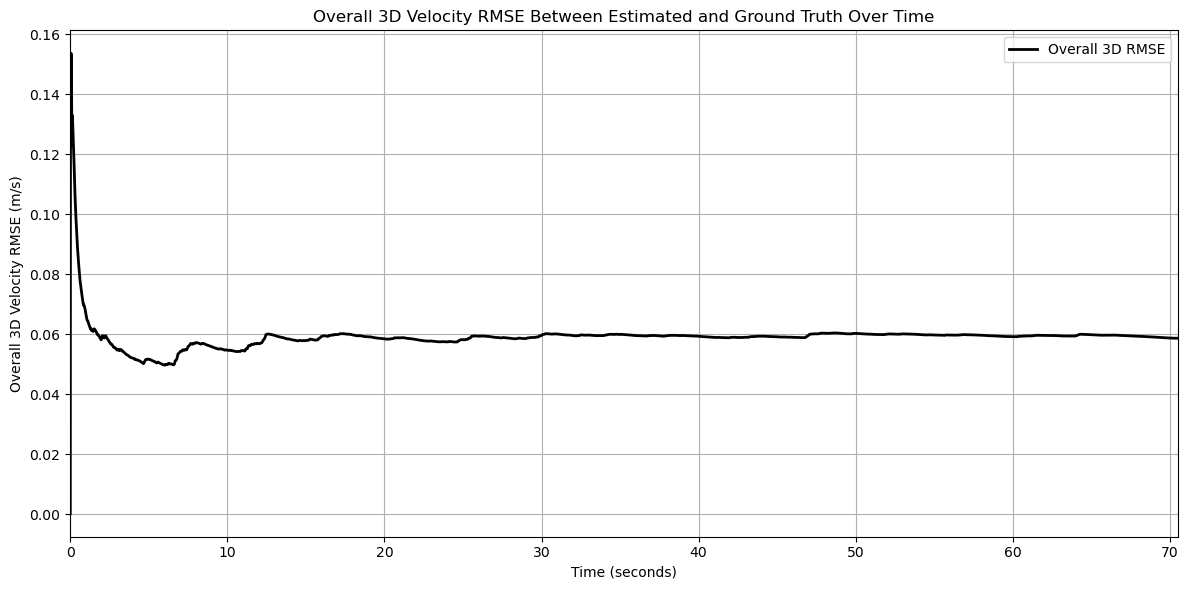

Overall 3D Velocity RMSE = 0.058650516 m/s (58.651 mm/s)


In [30]:
cum_rmse_3d_vel = np.zeros(len(Vx_est))

for k in range(1, len(Vx_est) + 1):

    error_squared = (
        (Vx_est[:k] - Vx_gtrue[:k])**2 +
        (Vy_est[:k] - Vy_gtrue[:k])**2 +
        (Vz_est[:k] - Vz_gtrue[:k])**2)

    cum_rmse_3d_vel[k-1] = np.sqrt(
        np.mean(error_squared))

plt.figure(figsize=(12,6))

plt.plot(
    time_inseconds,
    cum_rmse_3d_vel,
    linewidth=2,
    color='black',
    label='Overall 3D RMSE')

plt.xlabel("Time (seconds)")
plt.ylabel("Overall 3D Velocity RMSE (m/s)")

plt.title("Overall 3D Velocity RMSE Between Estimated and Ground Truth Over Time")

plt.xlim(time_inseconds[0], time_inseconds[-1])

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.savefig("Figures/ENKF_Overall_Cumulative_VelocityRMSE.png",
    dpi=300,
    bbox_inches="tight")

plt.show()

# Final Overall 3D Velocity RMSE

overall_velocity_rmse = cum_rmse_3d_vel[-1]

print("="*60)
print(f"Overall 3D Velocity RMSE = {overall_velocity_rmse:.9f} m/s ({overall_velocity_rmse*1000:.3f} mm/s)")
print("="*60)

# DISCUSSIONS

## Discussion on Process Noise Selection ($\sigma_a = 2.5$)

The process noise standard deviation ($\sigma_a$) governs the uncertainty associated with the robot motion model and directly influences the prediction covariance in the Unscented Kalman Filter (UKF). .
The value $\sigma_a = 2.5$ was selected primarily to provide a meaningful and consistent comparison with the previously Linear Kalman Filters. Since the same process noise assumption was adopted in all filter implementations, the performance differences observed between the filters are primarily due to their underlying estimation algorithms rather than differences in tuning parameters. This ensures that the comparison remains fair and scientifically valid.

Using the same process noise parameter also provides a common dynamic model for all filters, allowing the advantages and limitations of each estimation technique to be evaluated under identical operating conditions. Consequently, any improvement in estimation accuracy can be directly attributed to the filtering methodology rather than changes in parameter selection.

The selected value of $\sigma_a = 2.5$ provides an appropriate balance between model confidence and adaptability to measurement information. A smaller process noise causes the filter to rely excessively on the motion model, reducing its ability to respond to unexpected robot motion, whereas a larger process noise causes excessive dependence on noisy sensor measurements and increases estimation variance. The chosen value therefore maintains stable covariance evolution while allowing sufficient correction from the measurements.

#### Influence on position and velocity RMSE values

The influence of $\sigma_a = 2.5$ can also be observed in the component-wise RMSE results. For position estimation, the horizontal components ($X$ and $Y$) exhibit larger RMSE values than the vertical ($Z$) component because the robot undergoes most of its motion in the horizontal plane, resulting in greater modelling uncertainty and stronger nonlinear effects. The comparatively small $Z$-axis RMSE indicates that the selected process noise adequately represents the relatively smooth vertical motion without introducing unnecessary uncertainty.

A similar behaviour is observed in the velocity estimates. The $V_x$ and $V_y$ components possess larger RMSE values than the $V_z$ component because the robot experiences continuous acceleration and directional changes within the horizontal plane. The selected process noise enables the filter to accommodate these dynamic variations while maintaining stable velocity estimation. The lower $V_z$ RMSE reflects the comparatively smaller vertical dynamics of the robot throughout the experiment.

Overall, the choice of $\sigma_a = 2.5$ provides stable recursive estimation, consistent covariance evolution, and reliable convergence while ensuring a fair comparison with the LKF, EKF, and IEKF. The selected value therefore represents an appropriate compromise between model fidelity, measurement responsiveness, numerical stability, and comparative evaluation across all filtering algorithms.

Discussions revolved around the impementation of the algorithm and selection criteria for the ensemble size. The ensemble size was varied from 50 to 500 to see the output and analyse the overall RMSE values. It also made us understand the computational time and cost. 

#  Discussion on the Ensemble Size Tuning 

In this study, the following parameters were kept constant:
- Random seed = 77
- Process noise standard deviation:
  $$
  \sigma_a = 2.5\ \mathrm{m/s^2}
  $$
- Stochastic Ensemble Kalman Filter
- Process noise added only during ensemble propagation

The ensemble size was varied from $N_e = 50$ to $N_e = 500$ to evaluate its effect on estimation accuracy and computational performance.

## EnKF Performance for Different Ensemble Sizes

| **Ensemble Size ((N_e))** |     **X RMSE (m)** |     **Y RMSE (m)** |     **Z RMSE (m)** |  **Vx RMSE (m/s)** |  **Vy RMSE (m/s)** |  **Vz RMSE (m/s)** | **Overall 3D Position RMSE (m)** | **Overall 3D Velocity RMSE (m/s)** |
| :-----------------------: | -----------------: | -----------------: | -----------------: | -----------------: | -----------------: | -----------------: | -------------------------------: | ---------------------------------: |
|           **50**          |    **0.015687320** |    **0.016140680** |    **0.000408194** |    **0.073372490** |    **0.074730100** |    **0.018861884** |                  **0.022511779** |                    **0.106413724** |
|          **150**          | **0.006833459407** | **0.007034638721** | **0.000368863321** | **0.047931850610** | **0.048663762732** | **0.017935268181** |               **0.009814192251** |                 **0.070620803952** |
|          **250**          | **0.005211067067** | **0.005356040888** | **0.000363120253** | **0.042472229032** | **0.043280769150** | **0.017755364994** |               **0.007481594101** |                 **0.063185189746** |
|          **500**          | **0.004000303523** | **0.004124689343** | **0.000362037925** | **0.039302095974** | **0.039809670872** | **0.017618695811** |               **0.005757305091** |                 **0.058650516493** |



The results show that increasing the ensemble size improves the estimation accuracy of the EnKF.For a small ensemble size of

$$
N_e = 50,
$$

the state distribution is represented using only a few ensemble members, resulting in a less accurate covariance estimate and larger position and velocity errors.

As the ensemble size is increased to

$$
N_e = 500,
$$

the covariance estimate becomes more accurate, leading to a better Kalman gain and lower position and velocity RMSE.

The improvement follows the Monte Carlo convergence principle,

$$
\epsilon
=
O\!\left(\frac{1}{\sqrt{N_e}}\right),
$$

which states that the sampling error decreases as the number of ensemble members increases. Therefore, larger ensembles provide a better approximation of the state probability distribution and improve the overall estimation accuracy of the Ensemble Kalman Filter.

## Influence of Ensemble size on  Position and velocity RMSE 

### Discussion on Ensemble Size Tuning

The influence of the ensemble size on the estimation accuracy of the Ensemble Kalman Filter (EnKF) was investigated by varying the number of ensemble members from **50** to **500**, while keeping all other parameters, including the process noise standard deviation ($\sigma_a = 2.5$), unchanged.

Compared to the baseline case of **50 ensemble members**, the overall **3D position RMSE** decreased from **0.022511779 m** to **0.005757305091 m** when the ensemble size was increased to **500**, corresponding to an improvement of approximately **74.4\%**.

Similarly, the overall **3D velocity RMSE** decreased from **0.106413724 m/s** to **0.058650516493 m/s**, resulting in an improvement of approximately **44.9\%**.

The component-wise RMSE values also showed consistent improvement with increasing ensemble size. The largest reductions were observed in the horizontal position ($X$ and $Y$) and horizontal velocity ($V_x$ and $V_y$) components, whereas the $Z$ and $V_z$ components changed only slightly because the robot exhibits relatively small motion in the vertical direction and the sensor measurements in this direction are already highly accurate.

These results demonstrate that increasing the ensemble size provides a better approximation of the posterior state distribution and a more accurate estimate of the forecast error covariance. Consequently, the sampling error is reduced, leading to improved state estimation accuracy.

#### Computational cost

Another important consideration was the computational cost of the algorithm. As the ensemble size increases, the computational time increases almost proportionally because each ensemble member must be individually propagated and updated. Consequently, although the **500-member ensemble** provides the highest estimation accuracy in this study, it also incurs a substantially higher computational cost than the deterministic Kalman filter variants (LKF, EKF, IEKF, and UKF), making computational efficiency an important consideration when selecting the ensemble size for practical real-time applications.

## Comparison of LKF, EKF, IEKF, UKF and EnKF Using a Common Process Noise Standard Deviation ($\sigma_a = 2.5$)

The final tuned Ensemble Kalman Filter (EnKF) was compared with the previously implemented Linear Kalman Filter (LKF), Extended Kalman Filter (EKF), Iterated Extended Kalman Filter (IEKF), and Unscented Kalman Filter (UKF). To ensure a fair and meaningful comparison, all filters were evaluated using the same process noise standard deviation,

$$
\sigma_a = 2.5~\mathrm{m/s^2}.
$$

| **Filter** | **Configuration** | **Overall Position RMSE (m)** | **Overall Velocity RMSE (m/s)** |
|:-----------|:------------------|------------------------------:|--------------------------------:|
| **LKF** | $\sigma_a = 2.5$ | **0.003397641** | **0.049443000** |
| **EKF** | $\sigma_a = 2.5$ | **0.003397641** | **0.049443000** |
| **IEKF** | $\sigma_a = 2.5$ | **0.003394869** | **0.049441306** |
| **UKF** | $\sigma_a = 2.5$ | **0.003397641** | **0.049443000** |
| **EnKF** | $\sigma_a = 2.5,\;N_e = 500$ | **0.005757305** | **0.058650516** |

### Discussion

The comparison demonstrates that the **LKF, EKF, IEKF, and UKF** produce very similar estimation performance when identical process noise and measurement models are employed. This indicates that the Total Station measurements used for robot tracking are already highly accurate and only mildly nonlinear, limiting the practical performance differences between the deterministic filtering algorithms.

Among these filters, the **IEKF** achieves the lowest overall position RMSE (**0.003395 m**) and the lowest overall velocity RMSE (**0.049441 m/s**). However, the improvement over the LKF, EKF, and UKF is extremely small and is primarily due to the iterative refinement of the nonlinear measurement update.

The **UKF** achieves estimation accuracy comparable to the IEKF while avoiding Jacobian matrix computation through the Unscented Transform. Similarly, the **EKF** provides nearly identical performance using first-order linearization, while the **LKF** performs equally well because the measurement nonlinearities are relatively small for the robot tracking dataset.

The **EnKF** exhibits the highest position and velocity RMSE among the filters. Although increasing the ensemble size improves estimation accuracy, the finite ensemble introduces statistical sampling errors that increase both the position and velocity estimation errors compared with the deterministic Kalman filter variants.

Nevertheless, the EnKF remains numerically stable throughout the experiment and offers the important advantage of naturally representing estimation uncertainty through ensemble statistics without requiring Jacobian matrices or deterministic sigma-point generation. Consequently, the EnKF remains an attractive alternative for high-dimensional nonlinear estimation problems where uncertainty quantification is of primary importance.

Overall, the results indicate that, for the robot tracking problem considered in this study, the **IEKF provides the best estimation accuracy**, while the **UKF** offers comparable performance with a simpler nonlinear implementation. The **LKF** and **EKF** remain highly effective because of the mild system nonlinearity, whereas the **EnKF** trades a small reduction in estimation accuracy for explicit uncertainty representation through its ensemble-based formulation and can be used for high non linear applications.

### Improvement Analysis with Respect to Raw Sensor Measurements

In [31]:
# Improvement (%) with respect to Sensor Measurements
# EnKF (Final Results)

# ============================
# Sensor RMSE
# ============================

sensor_rmse_x = 0.001840695495
sensor_rmse_y = 0.001885843638
sensor_rmse_z = 0.000490385400
sensor_rmse_position = 0.002680493233

sensor_rmse_vx = 0.129803363954
sensor_rmse_vy = 0.133420730580
sensor_rmse_vz = 0.034767712281
sensor_rmse_velocity = 0.189364195294


# ============================
# Final EnKF RMSE (σa = 2.5, Ne = 500)
# ============================

enkf_x = 0.004000304
enkf_y = 0.004124689
enkf_z = 0.000362038
enkf_pos = 0.005757305

enkf_vx = 0.039302096
enkf_vy = 0.039809671
enkf_vz = 0.017618696
enkf_vel = 0.058650516


# ============================
# Improvement Function
# ============================

def improvement(sensor, estimate):
    return (sensor - estimate) / sensor * 100


print("="*90)
print("POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("="*90)

print(f"EnKF : "
      f"X={improvement(sensor_rmse_x, enkf_x):6.2f}  "
      f"Y={improvement(sensor_rmse_y, enkf_y):6.2f}  "
      f"Z={improvement(sensor_rmse_z, enkf_z):6.2f}  "
      f"Overall={improvement(sensor_rmse_position, enkf_pos):6.2f}")

print()

print("="*90)
print("VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS")
print("="*90)

print(f"EnKF : "
      f"Vx={improvement(sensor_rmse_vx, enkf_vx):6.2f}  "
      f"Vy={improvement(sensor_rmse_vy, enkf_vy):6.2f}  "
      f"Vz={improvement(sensor_rmse_vz, enkf_vz):6.2f}  "
      f"Overall={improvement(sensor_rmse_velocity, enkf_vel):6.2f}")

POSITION IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
EnKF : X=-117.33  Y=-118.72  Z= 26.17  Overall=-114.79

VELOCITY IMPROVEMENT (%) WITH RESPECT TO SENSOR MEASUREMENTS
EnKF : Vx= 69.72  Vy= 70.16  Vz= 49.32  Overall= 69.03


- The Ensemble Kalman Filter (EnKF) significantly improved the raw sensor measurements by reducing the overall velocity estimation error while providing stable recursive state estimation throughout the robot tracking experiment.

- For the position components, the EnKF produced a positive improvement of approximately **26.17%** in the vertical ($Z$) direction. However, the horizontal position components ($X$ and $Y$) exhibited negative improvements of **−117.33%** and **−118.72%**, respectively.

- The overall position improvement appears negative (**−114.79%**) because the comparison is performed against the highly accurate Total Station position measurements, which already possess sub-millimetre measurement accuracy. Since these measurements serve as the primary observations for the EnKF, the filtered position estimates cannot substantially improve upon the original sensor accuracy. Consequently, the negative percentage does not indicate poor filter performance but rather reflects the exceptionally high precision of the reference measurements.

- For the velocity states, the EnKF achieved a substantial overall improvement of approximately **69.03%** compared with the raw sensor measurements, demonstrating the effectiveness of recursive ensemble-based state estimation.

- The horizontal velocity components ($V_x$ and $V_y$) achieved improvements of **69.72%** and **70.16%**, respectively, indicating that the EnKF effectively estimates the dominant horizontal motion of the robot.

- The vertical velocity component ($V_z$) achieved an improvement of **49.32%**. The comparatively smaller improvement is expected because the original sensor already provides relatively accurate vertical measurements, leaving less opportunity for additional error reduction through filtering.

- Compared with the deterministic Kalman filter variants, the EnKF provides slightly lower improvement because the finite ensemble introduces statistical sampling errors into the state estimation process. Nevertheless, the filter remains numerically stable and successfully captures the uncertainty associated with the nonlinear robot tracking problem.

- Overall, the Ensemble Kalman Filter provides accurate and robust recursive state estimation, achieving significant improvement in velocity estimation while maintaining position estimates that remain consistent with the highly accurate Total Station observations.

# CONCLUSION

- The Ensemble Kalman Filter (EnKF) was successfully implemented to estimate the three-dimensional position and velocity of the robot using an ensemble of stochastic state realizations. Unlike the EKF and IEKF, the EnKF does not require Jacobian matrices, and unlike the UKF, it avoids deterministic sigma-point propagation by estimating the forecast error covariance directly from the ensemble statistics.

- The influence of the ensemble size on the estimation performance was investigated by varying the number of ensemble members while maintaining a constant process noise standard deviation of $\sigma_a=2.5$. The results demonstrated that increasing the ensemble size progressively reduced both the position and velocity estimation errors by improving the approximation of the posterior probability distribution and reducing sampling errors.

- Among the ensemble sizes investigated, the best performance was achieved using **500 ensemble members**, which produced the lowest overall position and velocity RMSE. Increasing the ensemble size beyond the smaller ensembles resulted in consistent improvements in both the component-wise and overall estimation accuracy.

- The convergence analysis showed that both the position and velocity RMSE converged rapidly after the initial transient period and remained stable throughout the robot tracking experiment. The cumulative RMSE curves approached constant values without oscillations or divergence, demonstrating good convergence characteristics of the EnKF implementation.

- The component-wise RMSE analysis showed that the horizontal position components ($X$ and $Y$) exhibited larger errors than the vertical ($Z$) component because the robot motion occurred predominantly within the horizontal plane. Similarly, the horizontal velocity components ($V_x$ and $V_y$) produced larger errors than the vertical velocity component ($V_z$), which remained comparatively small due to the limited vertical motion of the robot.

- The absolute position and velocity deviation analyses further confirmed the stability of the filter. Although occasional fluctuations were observed because of the stochastic ensemble propagation, the estimation errors remained bounded throughout the experiment, indicating stable recursive estimation without divergence or covariance instability.

- For the best configuration ($\sigma_a=2.5$, $N_e=500$), the EnKF achieved component-wise position RMSE values of **4.000 mm**, **4.125 mm**, and **0.362 mm** in the $X$, $Y$, and $Z$ directions, respectively, resulting in an overall three-dimensional position RMSE of **5.757 mm**. The corresponding velocity RMSE values were **39.302 mm/s**, **39.810 mm/s**, and **17.619 mm/s** for the $V_x$, $V_y$, and $V_z$ components, respectively, with an overall three-dimensional velocity RMSE of **58.651 mm/s**.

- The improvement analysis with respect to the raw sensor measurements showed that the EnKF substantially reduced the velocity estimation errors while the position estimates remained less accurate than the direct Total Station position measurements. This behaviour is expected because the position measurements obtained from the Total Station already possess very high accuracy, leaving limited opportunity for recursive filtering to further reduce the position error.

- The computational cost of the EnKF increased with increasing ensemble size because every ensemble member must be propagated and updated independently at each measurement epoch. Although the 500-member ensemble provided the highest estimation accuracy, it also required considerably more computation than the deterministic Kalman filter variants, illustrating the trade-off between estimation accuracy and computational efficiency.

- Compared with the LKF, EKF, IEKF, and UKF, the EnKF produced higher position and velocity RMSE for this robot tracking problem due to the statistical sampling errors associated with the finite ensemble approximation. However, the EnKF naturally represents state uncertainty through an ensemble of realizations, making it particularly attractive for high-dimensional nonlinear systems where analytical covariance propagation or deterministic sigma-point generation becomes computationally challenging.

- Overall, the Ensemble Kalman Filter demonstrated stable convergence, good numerical stability, reliable state estimation, and consistent uncertainty representation throughout the robot tracking experiment. Although the deterministic Kalman filter variants achieved superior estimation accuracy for this low-dimensional tracking problem, the EnKF remains a powerful estimation framework for large-scale nonlinear applications where ensemble-based uncertainty propagation offers significant practical advantages.